# 03 — Error analysis: where the model is wrong, and why

HANDOFF section 9 makes an error-analysis notebook part of the Phase 2 checkpoint. This one
works on **out-of-fold** ridge predictions over the live table: every row is predicted by a
model that never saw its `dedup_key`, so these are honest errors, not training residuals.

Ridge is the reference here, not LightGBM. LightGBM v1 merged into `main` on 2026-11-18 and
scores better (MAE $119 on KW rows vs ridge $136), but the point of this notebook is to find
which *segments and missing features* cost money. Those conclusions are properties of the data,
not of the learner, so they carry over — and they say what to fix before tuning any model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

from housing.db import connect
from housing.model.baseline import FEATURES, fit_predict_ridge
from housing.model.dataset import BOOLEANS, CATEGORICALS, GROUP, NUMERICS, TARGET, load_training

pd.set_option("display.width", 140)
conn = connect()
df, report = load_training(conn)
df = df.reset_index(drop=True)
print(report)

clean table: kept 6595 rows; dropped 2559 (no_price=232, no_location=0, out_of_region=648, wanted_ad=20, per_term_price=0, bad_bedrooms=0, no_target=1, target_out_of_range=68, room_price_out_of_range=67, duplicates=1523); bathrooms set NA on 0


In [2]:
def oof(frame, fit_predict=fit_predict_ridge, n_splits=5):
    """Out-of-fold predictions, grouped by dedup_key so no address leaks across folds."""
    pred = np.full(len(frame), np.nan)
    for tr, te in GroupKFold(n_splits=n_splits).split(frame, groups=frame[GROUP]):
        pred[te] = fit_predict(frame.iloc[tr], frame.iloc[te])
    return pred

y = df[TARGET].astype(float)
df["pred"] = oof(df)
df["err"] = df["pred"] - y                      # positive = model asks too much
df["abs_err"] = df["err"].abs()
df["ape"] = df["abs_err"] / y * 100
df["log_res"] = np.log(y) - np.log(df["pred"])  # the residual the range is built from

print(f"out-of-fold MAE ${df['abs_err'].mean():.0f} | MAPE {df['ape'].mean():.1f}% | "
      f"median abs err ${df['abs_err'].median():.0f} | n={len(df)}")

out-of-fold MAE $146 | MAPE 14.5% | median abs err $102 | n=6595


## 1. Error by segment

`min_n=30` so a handful of rows cannot invent a conclusion. Sorted worst-first: the top of
each table is where the money is.

In [3]:
def by(col, min_n=30):
    """Out-of-fold error grouped by one column, worst MAE first."""
    g = df.groupby(col, dropna=False).agg(
        n=("abs_err", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"),
        bias=("err", "mean"), median_price=(TARGET, "median"))
    return g[g["n"] >= min_n].sort_values("MAE", ascending=False).round(1)

by("unit_type")

,n,MAE,MAPE,bias,median_price
unit_type,,,,,
1bed,1439,201.5,13.8,-25.9,1600.0
studio,148,184.0,14.1,0.5,1327.5
room,1259,172.2,21.5,-23.2,790.0
house,732,160.8,16.2,-32.4,885.0
2bed,1754,113.4,11.8,-15.2,950.0
3plus,1263,90.1,11.0,-10.5,800.0


In [4]:
by("bedrooms")

,n,MAE,MAPE,bias,median_price
bedrooms,,,,,
1,1817,219.4,16.0,-41.6,1549.0
<NA>,707,149.5,20.9,25.1,750.0
5,178,143.8,19.0,-51.2,725.0
2,2063,121.2,12.5,-26.4,950.0
4,464,113.3,14.9,24.5,750.0
3,1348,95.0,11.2,-11.9,833.3


In [5]:
by("city")

,n,MAE,MAPE,bias,median_price
city,,,,,
guelph,430,172.8,15.0,-28.9,1071.0
hamilton,1950,159.9,15.0,-20.9,988.5
kitchener-waterloo,2641,141.4,14.3,-19.9,949.5
london,1574,130.1,14.1,-15.5,850.0


In [6]:
by("lease_term")

,n,MAE,MAPE,bias,median_price
lease_term,,,,,
sublet_4mo,224,188.4,20.5,0.7,877.5
month_to_month,238,178.7,20.8,-38.2,850.0
8mo,54,178.5,23.2,-5.3,797.5
12mo,2584,149.6,13.8,-20.2,1000.0
unknown,3495,138.4,14.0,-19.6,900.0


In [7]:
by("building_type")

,n,MAE,MAPE,bias,median_price
building_type,,,,,
purpose_built_student,114,199.8,18.8,-7.0,1079.0
unknown,3850,148.7,13.8,-21.8,1000.0
house,2631,140.4,15.4,-17.2,859.8


## 2. Error against price level

MAE in dollars rises with price almost mechanically, so read MAPE and **bias** here. A
systematic bias by decile means the model is regressing toward the middle: too generous at
the bottom, too stingy at the top. That is the single most visible failure to a user, because
the cheap and expensive ends are exactly where someone wants a verdict.

In [8]:
df["price_decile"] = pd.qcut(y, 10, labels=False, duplicates="drop") + 1
dec = df.groupby("price_decile").agg(
    n=("abs_err", "size"), price_lo=(TARGET, "min"), price_hi=(TARGET, "max"),
    MAE=("abs_err", "mean"), MAPE=("ape", "mean"), bias=("err", "mean")).round(1)
dec

,n,price_lo,price_hi,MAE,MAPE,bias
price_decile,,,,,,
1,674,300.0,675.0,188.7,34.7,184.8
2,686,680.0,750.0,105.9,14.6,85.3
3,645,750.3,816.7,85.7,10.8,44.8
4,708,820.0,875.0,86.6,10.2,28.0
5,589,876.0,933.3,78.7,8.7,-12.7
6,681,934.0,1025.0,92.4,9.4,-41.0
7,655,1026.7,1175.0,143.0,13.0,-82.9
8,705,1177.0,1400.0,208.6,16.3,-40.8
9,614,1405.0,1650.0,151.9,9.9,-69.7


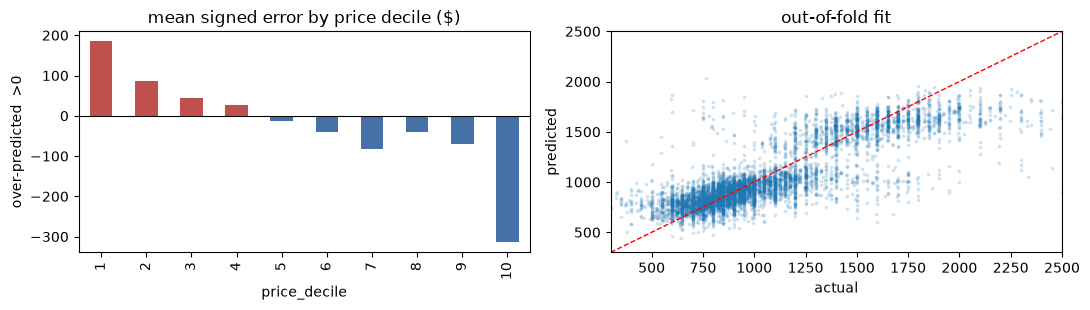

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
dec["bias"].plot.bar(ax=axes[0], color=np.where(dec["bias"] > 0, "#c0504d", "#4472a8"))
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_title("mean signed error by price decile ($)")
axes[0].set_ylabel("over-predicted  >0")
axes[1].scatter(y, df["pred"], s=3, alpha=0.15)
lims = [y.min(), y.quantile(0.999)]
axes[1].plot(lims, lims, "r--", lw=1); axes[1].set_xlim(*lims); axes[1].set_ylim(*lims)
axes[1].set_xlabel("actual"); axes[1].set_ylabel("predicted"); axes[1].set_title("out-of-fold fit")
plt.tight_layout()

## 3. What the honest price range has to be

The app promises a range, not a point (HANDOFF section 2). Its width comes from the spread of
out-of-fold **log** residuals: the 10th-to-90th band. One shared band is only right if every
unit type is equally predictable — this is the independent check on the Mondrian (per-type)
calibration now in `housing.model.lgbm`.

In [10]:
q = df["log_res"].quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
shared_width = np.exp(q[0.90]) / np.exp(q[0.10])
print(q.round(3).to_string())
print(f"\nshared 10-90 band is a factor of {shared_width:.2f}x "
      f"(a $1,000 expected price becomes roughly "
      f"${1000 * np.exp(q[0.10]):.0f} to ${1000 * np.exp(q[0.90]):.0f})")

0.05   -0.292
0.10   -0.214
0.25   -0.102
0.50    0.000
0.75    0.106
0.90    0.218
0.95    0.301

shared 10-90 band is a factor of 1.54x (a $1,000 expected price becomes roughly $807 to $1243)


In [11]:
spread = df.groupby("unit_type")["log_res"].quantile([0.10, 0.90]).unstack()
spread.columns = ["p10", "p90"]
spread["n"] = df.groupby("unit_type")["log_res"].size()
spread["band width x"] = (np.exp(spread["p90"]) / np.exp(spread["p10"]))
spread["vs shared"] = spread["band width x"] - shared_width
spread[spread["n"] >= 30].sort_values("band width x", ascending=False).round(2)

,p10,p90,n,band width x,vs shared
unit_type,,,,,
room,-0.33,0.32,1259,1.91,0.37
house,-0.22,0.29,732,1.66,0.12
studio,-0.21,0.18,148,1.48,-0.06
1bed,-0.18,0.19,1439,1.46,-0.08
2bed,-0.17,0.18,1754,1.42,-0.12
3plus,-0.18,0.16,1263,1.40,-0.14


## 4. Does missing data explain the misses?

Every clean row is allowed NAs; the ridge median-imputes them. If error climbs with the number
of missing inputs, the fix is better extraction, not a better model.

In [12]:
df["n_missing"] = df[CATEGORICALS + NUMERICS + BOOLEANS].isna().sum(axis=1)
by("n_missing", min_n=20)

,n,MAE,MAPE,bias,median_price
n_missing,,,,,
1,128,181.0,18.1,12.3,1068.8
13,72,170.7,21.9,20.3,750.0
10,165,169.5,21.9,-17.2,750.0
7,376,165.7,15.4,-27.5,948.5
4,429,159.4,15.9,-19.6,1025.0
2,632,157.4,15.2,-11.6,992.5
6,599,154.9,14.6,-30.2,950.0
12,150,149.9,19.9,0.6,750.0
11,166,149.1,19.8,0.1,750.0


In [13]:
miss = pd.DataFrame({
    "null %": df[CATEGORICALS + NUMERICS + BOOLEANS].isna().mean().mul(100).round(1),
})
miss["MAE when present"] = [df.loc[df[c].notna(), "abs_err"].mean() for c in miss.index]
miss["MAE when null"] = [df.loc[df[c].isna(), "abs_err"].mean() for c in miss.index]
miss["penalty"] = (miss["MAE when null"] - miss["MAE when present"]).round(1)
miss.sort_values("penalty", ascending=False).round(1)

,null %,MAE when present,MAE when null,penalty
utilities_included,7.5,144.1,172.6,28.5
year_built_after_2018,98.5,125.5,146.6,21.1
neighbourhood,11.7,143.9,164.1,20.2
landlord_type,16.5,142.9,163.1,20.2
bathrooms,13.5,143.8,161.6,17.8
laundry_in_unit,13.6,144.0,160.6,16.6
walk_uw_min,60.0,141.4,149.5,8.0
walk_laurier_min,60.0,141.4,149.5,8.0
ion_distance_m,60.0,141.4,149.5,8.0
bedrooms,10.7,145.9,149.5,3.6


## 5. The worst misses

Reading actual rows is the only way to find a rule the extractor is getting wrong. Anything
that repeats here is a parser bug or a missing feature, not model error.

In [14]:
worst = df.nlargest(15, "abs_err")[
    ["city", "unit_type", "bedrooms", "bathrooms", "lease_term", "building_type",
     "neighbourhood", "sqft", TARGET, "pred", "err", "n_missing"]]
worst.round(0)

,city,unit_type,bedrooms,bathrooms,lease_term,building_type,neighbourhood,sqft,price_per_bedroom,pred,err,n_missing
5092,hamilton,3plus,3,3.0,unknown,unknown,L8T,NaN,2665.0,963.0,-1702.0,8
2332,hamilton,2bed,2,4.0,unknown,unknown,L8P,NaN,2950.0,1267.0,-1683.0,8
4041,london,3plus,3,3.0,unknown,unknown,N6K,NaN,2500.0,903.0,-1597.0,8
185,kitchener-waterloo,studio,1,1.0,12mo,unknown,N2G,500.0,3000.0,1427.0,-1573.0,2
80,kitchener-waterloo,house,2,6.0,12mo,house,N2E,1866.0,2850.0,1303.0,-1547.0,2
5653,hamilton,house,1,2.0,12mo,house,NaN,1000.0,2450.0,1143.0,-1307.0,6
4715,guelph,3plus,3,3.0,unknown,unknown,N1H,NaN,2333.0,1046.0,-1287.0,7
1604,kitchener-waterloo,1bed,1,4.0,sublet_4mo,unknown,NaN,1202.0,767.0,2038.0,1271.0,2
112,kitchener-waterloo,1bed,1,2.0,12mo,unknown,N2L,115.0,600.0,1863.0,1263.0,2
2410,hamilton,1bed,1,2.0,12mo,unknown,L8S,100.0,595.0,1828.0,1233.0,5


In [15]:
print("worst-miss composition vs table share (%):")
cmp = pd.DataFrame({
    "worst 5% share": df.nlargest(int(len(df) * 0.05), "abs_err")["unit_type"]
                        .value_counts(normalize=True).mul(100),
    "table share": df["unit_type"].value_counts(normalize=True).mul(100),
}).round(1)
cmp["over-represented by"] = (cmp["worst 5% share"] - cmp["table share"]).round(1)
cmp

worst-miss composition vs table share (%):


,worst 5% share,table share,over-represented by
unit_type,,,
1bed,44.1,21.8,22.3
2bed,9.1,26.6,-17.5
3plus,4.3,19.2,-14.9
house,18.5,11.1,7.4
room,21.0,19.1,1.9
studio,3.0,2.2,0.8


## 6. Findings

Out-of-fold ridge on the live table: **MAE $146, MAPE 14.5%**, but the median absolute error is
only **$102**. The mean is dragged by a tail, so the average is the wrong number to quote.

**1-bedrooms are the problem segment.** MAE $201 on 1,439 rows, and they are **44% of the worst
5% of misses while being 21.8% of the table** — over-represented by 22 points. Split by bedroom
count the same thing shows: `bedrooms == 1` has MAE $219. Section 5 suggests why — several of the
worst rows are 1-beds with `bathrooms` of 2 or 4 and `sqft` of 100–115, which are extraction
bugs, not hard listings.

**The model regresses hard to the mean.** Decile 1 ($300–675) is over-predicted by **+$185**;
decile 10 ($1,655–3,000) is under-predicted by **−$314**. A user with a genuinely cheap room is
told it is overpriced, and a user with a genuinely expensive unit is told it is a bargain —
the verdict is wrong in the two cases where it matters most. This is the top modelling priority
and the main thing a tree model should fix.

**Per-unit-type ranges are justified.** The shared 10–90 band is a factor of **1.54x** ($1,000
expected → $807–$1,243). But rooms need **1.91x** and 3+ bedrooms only **1.40x**. One shared band
is simultaneously too narrow for rooms and too wide for larger units — exactly what the Mondrian
calibration in `housing.model.lgbm` was built for. **Confirmed here from ridge residuals, i.e.
independently of the model that uses it.**

**Extraction beats modelling for the next win.** Rows where a field is NULL cost real money:
`utilities_included` **+$28.5** MAE, `neighbourhood` **+$20.2**, `landlord_type` **+$20.2**,
`bathrooms` **+$17.8**, `laundry_in_unit` **+$16.6**. Each is a parser improvement, not a model
change, and `utilities_included` is only 7.5% null — closing that last bit is cheap.

**Two features are dead weight.** `year_built_after_2018` is **98.5% NULL** and
`internet_included` is 90.1% NULL; `sqft` is 62.7% NULL. Their negative "penalty" means they are
present mostly on rows that were easy anyway, so they carry no usable signal. They should be
dropped or re-derived before they are tuned.

**Short leases are unpredictable.** Sublets MAPE 20.5%, month-to-month 20.8%, 8-month 23.2%,
against 13.8% for 12-month. `purpose_built_student` buildings are also poor (MAE $200 on 114
rows). Both are small, high-variance segments that the range — not the point estimate — has to
absorb.

## 7. What to do next, in order

1. **Keep `--archive` off** for the shipping model (notebook 02).
2. **Fix the 1-bed/`bathrooms`/`sqft` extraction bugs** surfaced in section 5, then re-run this
   notebook; part of the $201 MAE is parser noise, not model error.
3. **Re-run this notebook against LightGBM** (merged 2026-11-18) by passing its fit/predict to
   `oof()` — the decile bias above is the specific thing a tree model should fix, and this is the
   measurement that proves it did. Use `--eval-city` semantics: score KW rows only.
4. **Close the `utilities_included`, `neighbourhood`, `landlord_type` and `bathrooms` gaps** in
   extraction before adding any new feature.
5. **Drop or re-derive `year_built_after_2018` and `internet_included`.**